# 02 · Modelling, tuning and evaluation
Lifecycle steps 2-7. All of the logic lives in `scripts/train.py` and `src/kiranbazaar/` so that the notebook, the
apps and the saved model share **one** code path. This notebook runs the script and explains each step.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kiranbazaar import config as C, features as F
FIG = C.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

## Pre-processing Pipeline (fitted on training data only)
`DerivedFeatures` (cyclical month, relative momentum, fuel pressure, acceleration) → `ColumnTransformer`
[numeric: median imputation + missing indicators + StandardScaler | categorical: most-frequent imputation + One-Hot] → model.

Lag/rolling features are computed per series from **past months only**, so they hold no future information.

In [2]:
from kiranbazaar import modeling as M
M.make_pipeline(M.LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('derive', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_p

## Train / validation / test split: chronological (time series)
70 / 15 / 15 by month: training ends Jan 2022, validation covers the 2022-24 inflation shock, test is the most recent ~2 years.
A random split would leak the future into training (neighbouring months are near-identical).

In [3]:
lab = F.labelled(F.build_features(*F.load_raw()))
tr, va, te = F.time_split(lab)
pd.DataFrame({n: {"rows": len(d), "from": d.date.min().date(), "to": d.date.max().date(), "spike rate": round(d[C.TARGET_CLF].mean(), 3)}
              for n, d in [("train", tr), ("validation", va), ("test", te)]}).T

,rows,from,to,spike rate
train,6646,2014-01-15,2022-11-15,0.149
validation,1427,2022-12-15,2024-09-15,0.193
test,1495,2024-10-15,2026-08-15,0.126


## Training all models
Baselines: (a) class prior, (b) persistence rule ("jumped last month, so jumps again").
Course algorithms: Logistic Regression, PCA + Logistic Regression, KNN, Gaussian Naive Bayes, SVM (RBF), Decision Tree, Random Forest, Bagging, Gradient Boosting. Plus Linear/Ridge regression for the companion "expected % change" task.

Tuning: **5-fold `TimeSeriesSplit`** cross-validation (forward-chaining, so each fold validates on later months) with `GridSearchCV` / `RandomizedSearchCV`, scored on ROC-AUC.

In [4]:
%run ../scripts/train.py

split: {
 "train": {
  "rows": 6646,
  "start": "2014-01-15",
  "end": "2022-11-15",
  "spike_rate": 0.1494
 },
 "validation": {
  "rows": 1427,
  "start": "2022-12-15",
  "end": "2024-09-15",
  "spike_rate": 0.1927
 },
 "test": {
  "rows": 1495,
  "start": "2024-10-15",
  "end": "2026-08-15",
  "spike_rate": 0.1258
 }
}


Logistic Regression          cv=0.719 val_auc=0.706 val_f1=0.432 (3s)


PCA + Logistic Regression    cv=0.729 val_auc=0.704 val_f1=0.431 (1s)


KNN                          cv=0.729 val_auc=0.690 val_f1=0.413 (2s)


Naive Bayes                  cv=0.730 val_auc=0.715 val_f1=0.444 (1s)


SVM (RBF)                    cv=0.737 val_auc=0.717 val_f1=0.426 (46s)


... (6 outputs left out)

Ridge Regression             val_mae=0.0490 r2=-0.003


Random Forest Regressor      val_mae=0.0451 r2=0.049


Gradient Boosting Regressor  val_mae=0.0446 r2=0.041


                                 model     mae    rmse      r2
0  Gradient Boosting Regressor (final)  0.0349  0.0643  0.0530
1                 Baseline: train mean  0.0386  0.0663 -0.0063
2             Baseline: no change (0%)  0.0360  0.0662 -0.0044
done in 310s


## Model comparison (validation set: used for model selection)

In [5]:
R = C.ROOT / "reports"
cmp = pd.read_csv(R / "classification_comparison_validation.csv")
cmp.drop(columns="best_params").sort_values("val_roc_auc", ascending=False).round(3)

,model,cv_roc_auc,train_roc_auc,val_roc_auc,val_pr_auc,val_f1,val_precision,val_recall,fit_s
9,Bagging (Decision Trees),0.761,0.888,0.755,0.389,0.475,0.384,0.622,23.1
8,Random Forest,0.770,0.857,0.739,0.371,0.463,0.355,0.665,73.6
10,Gradient Boosting,0.745,0.963,0.728,0.367,0.428,0.289,0.825,55.5
6,SVM (RBF),0.737,0.848,0.717,0.341,0.426,0.284,0.847,45.7
5,Naive Bayes,0.730,0.759,0.715,0.303,0.444,0.307,0.800,0.6
2,Logistic Regression,0.719,0.793,0.706,0.310,0.432,0.315,0.684,2.9
3,PCA + Logistic Regression,0.729,0.772,0.704,0.309,0.431,0.294,0.807,1.0
7,Decision Tree,0.712,0.838,0.699,0.317,0.436,0.312,0.724,1.7
4,KNN,0.729,1.000,0.690,0.323,0.413,0.279,0.793,1.7
1,Baseline: persistence rule,NaN,0.614,0.615,0.261,0.379,0.369,0.389,0.0


In [6]:
cmp[["model", "best_params"]]

,model,best_params
0,Baseline: class prior,-
1,Baseline: persistence rule,-
2,Logistic Regression,"{""C"": 0.01}"
3,PCA + Logistic Regression,"{""C"": 0.1, ""pca__n_components"": 10}"
4,KNN,"{""n_neighbors"": 61, ""weights"": ""distance""}"
5,Naive Bayes,"{""var_smoothing"": 0.1}"
6,SVM (RBF),"{""C"": 0.3, ""gamma"": 0.01}"
7,Decision Tree,"{""max_depth"": 5, ""min_samples_leaf"": 100}"
8,Random Forest,"{""max_depth"": 6, ""max_features"": ""sqrt"", ""min_..."
9,Bagging (Decision Trees),"{""max_features"": 0.5, ""max_samples"": 0.3}"


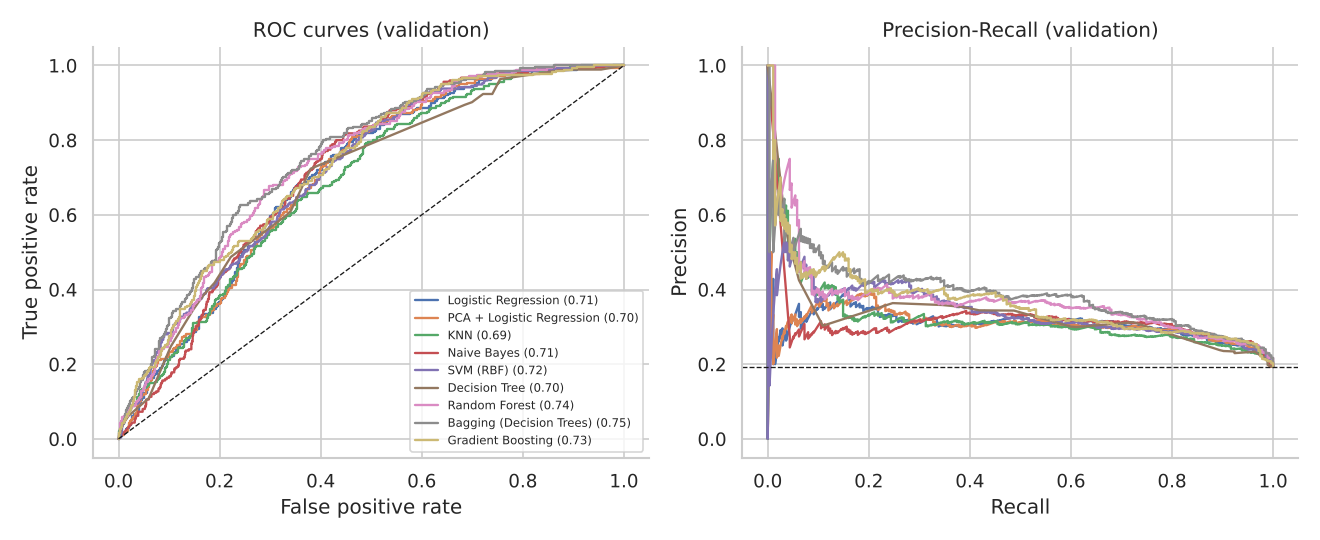

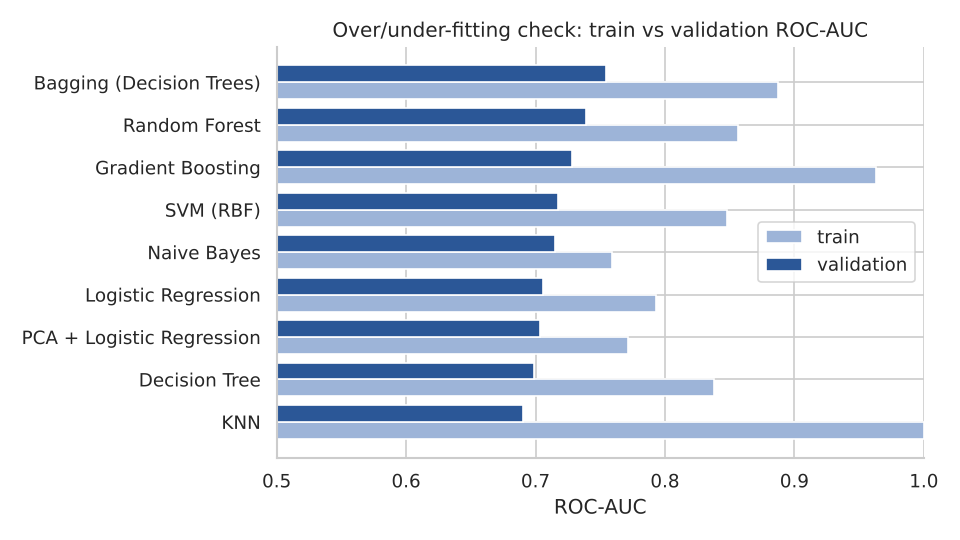

In [7]:
from IPython.display import Image, display
display(Image(FIG / "10_roc_pr_validation.png")); display(Image(FIG / "12_train_vs_val_auc.png"))

**Over/under-fitting (read the train vs validation chart).**
* **KNN** reaches train ROC-AUC 1.00 against 0.69 on validation: distance weighting makes every training point its own nearest neighbour, so it memorises. That is clear over-fitting.
* **Gradient Boosting** (0.96 → 0.73) also over-fits; CV chose a small learning rate and large leaves, but deep trees still memorise.
* **Logistic Regression, PCA + LR and Naive Bayes** show small gaps (≈ 0.05-0.09) and low training scores: they are *high-bias* models that under-fit the non-linear signal.
* **Bagging** sits in between (0.89 → 0.76): averaging trees fitted on 30 % bootstrap samples with 50 % of the features reduces variance. It is selected for the best validation ROC-AUC and PR-AUC.

Validation is also harder than training because of the **2022-24 inflation shock** (spike rate 19 % vs 15 %).
## Final evaluation on the held-out test set (reported once)

final model: Bagging (Decision Trees) | decision threshold: 0.266


,model,roc_auc,pr_auc,f1,precision,recall
0,Bagging (Decision Trees) (final),0.818,0.395,0.487,0.417,0.585
1,Baseline: persistence rule,0.619,0.194,0.332,0.330,0.335
2,Baseline: class prior,0.500,0.126,0.000,0.000,0.000


              precision    recall  f1-score   support

    no spike       0.94      0.88      0.91      1307
       spike       0.42      0.59      0.49       188

    accuracy                           0.84      1495
   macro avg       0.68      0.73      0.70      1495
weighted avg       0.87      0.84      0.86      1495



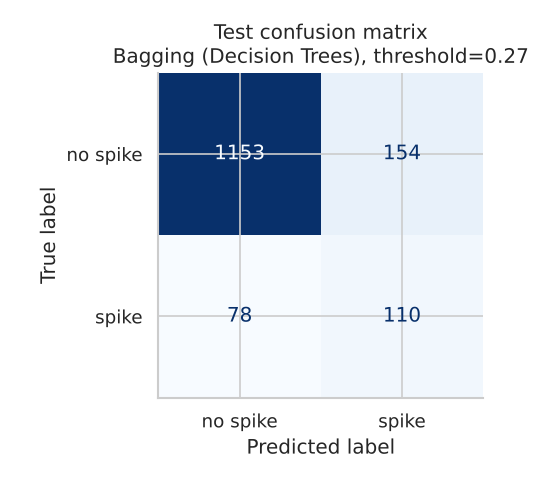

In [8]:
import json
meta = json.loads((C.MODELS_DIR / "metadata.json").read_text())
print("final model:", meta["classifier"], "| decision threshold:", round(meta["decision_threshold"], 3))
display(pd.read_csv(R / "classification_test.csv").round(3))
print((R / "classification_report_test.txt").read_text())
display(Image(FIG / "11_confusion_matrix_test.png"))

## Error analysis

,commodity,rows,spike_rate,roc_auc,f1
8,"Rice (basmati, broken)",115.0,0.043,0.504,0.286
1,Eggs,115.0,0.348,0.516,0.567
9,Rice (coarse),115.0,0.035,0.516,0.000
0,Beans(mash),115.0,0.061,0.519,0.267
12,Wheat flour,115.0,0.183,0.562,0.320
2,Ghee (artificial),115.0,0.043,0.644,0.000
11,Wheat,115.0,0.296,0.666,0.478
10,Sugar,115.0,0.122,0.745,0.200
5,Milk,115.0,0.026,0.765,0.000
7,Poultry,115.0,0.400,0.774,0.667


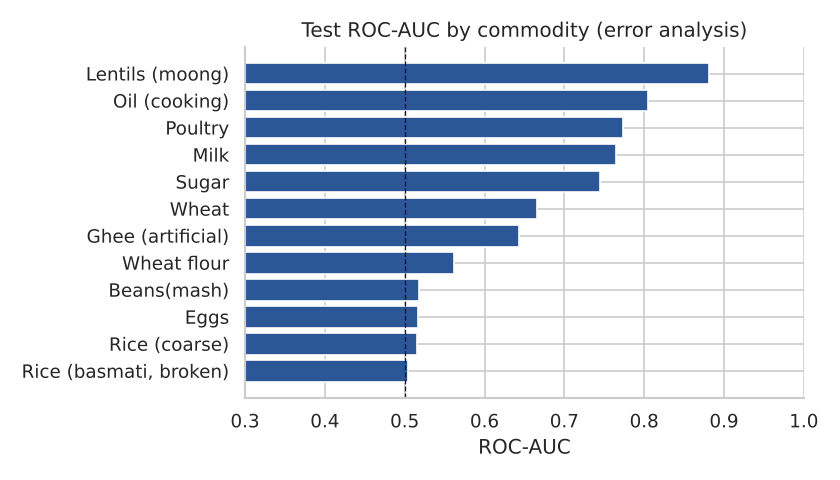

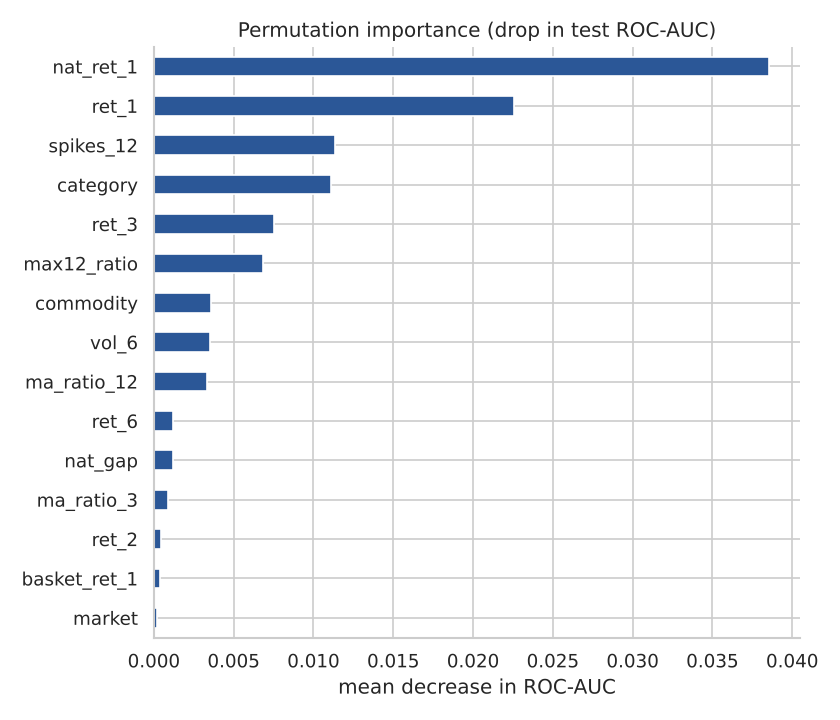

In [9]:
display(pd.read_csv(R / "test_by_commodity.csv").round(3).sort_values("roc_auc"))
display(Image(FIG / "14_test_auc_by_commodity.png")); display(Image(FIG / "13_permutation_importance.png"))

## Companion regression: expected next-month % change (MAE / RMSE / R²)

,model,train_mae,val_mae,val_rmse,val_r2
0,Baseline (train mean),0.0385,0.0465,0.0734,-0.0016
1,Linear Regression,0.0374,0.0503,0.0748,-0.0418
2,Ridge Regression,0.0374,0.0490,0.0734,-0.0032
3,Random Forest Regressor,0.0281,0.0451,0.0715,0.0486
4,Gradient Boosting Regressor,0.0315,0.0446,0.0718,0.0410


,model,mae,rmse,r2
0,Gradient Boosting Regressor (final),0.0349,0.0643,0.0530
1,Baseline: train mean,0.0386,0.0663,-0.0063
2,Baseline: no change (0%),0.0360,0.0662,-0.0044


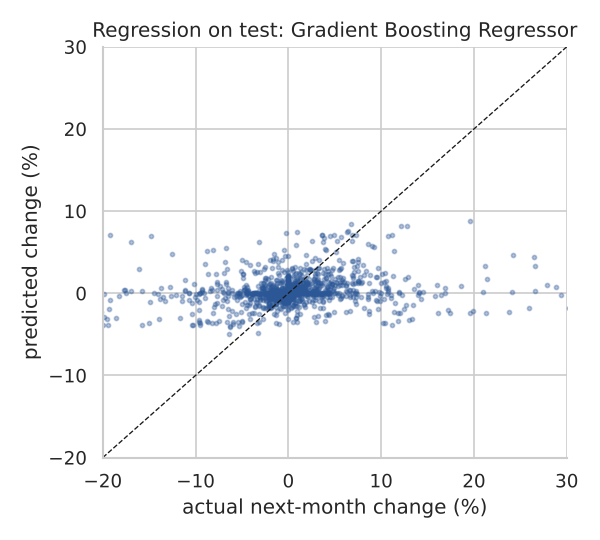

In [10]:
display(pd.read_csv(R / "regression_comparison_validation.csv").drop(columns="best_params").round(4))
display(pd.read_csv(R / "regression_test.csv").round(4)); display(Image(FIG / "15_regression_test_scatter.png"))

Monthly price changes are close to a random walk, so R² is low and the regression only slightly beats "no change". This is the
main argument for framing the problem as **classification** (is a spike coming?), where the models clearly beat the baselines.
## Saved artefacts

In [11]:
import joblib
clf = joblib.load(C.MODELS_DIR / "spike_classifier.joblib")
latest = F.build_features(*F.load_raw()); latest = latest[latest.date == latest.date.max()]
latest.assign(p_spike=clf.predict_proba(latest[M.FEATURES])[:, 1].round(3))[["date", "market", "commodity", "price", "p_spike"]] \
      .sort_values("p_spike", ascending=False).head(10)

,date,market,commodity,price,p_spike
11841,2026-09-15,Lahore,Eggs,248.0,0.331
11854,2026-09-15,Multan,Eggs,234.0,0.309
11849,2026-09-15,Lahore,Rice (coarse),217.0,0.302
11890,2026-09-15,Quetta,Wheat,129.0,0.287
11867,2026-09-15,Peshawar,Eggs,267.0,0.278
11828,2026-09-15,Karachi,Eggs,260.0,0.278
11880,2026-09-15,Quetta,Eggs,252.0,0.271
11834,2026-09-15,Karachi,Poultry,350.0,0.267
11888,2026-09-15,Quetta,Rice (coarse),160.0,0.259
11847,2026-09-15,Lahore,Poultry,321.0,0.242
